## 1. Импорты и настройки

In [1]:
import pickle

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import average_precision_score, roc_auc_score
from sqlalchemy.dialects.postgresql import ARRAY, BIGINT

from database import postgres_connection

## 2. Загружаем данные

In [2]:
df_user_data = pd.read_sql("SELECT * FROM public.user_data", con=postgres_connection())
df_post_text = pd.read_sql("SELECT * FROM public.post_text_df", con=postgres_connection())

df_feed_data = pd.read_sql(
    "SELECT timestamp, user_id, post_id, action, target FROM public.feed_data "
    "WHERE action = 'view' AND target IS NOT NULL ORDER BY timestamp "
    f"LIMIT 3500000",
    con=postgres_connection(),
)

# преобразуем типы данных для оптимизации памяти
df_feed_data['timestamp'] = pd.to_datetime(df_feed_data['timestamp'])
df_feed_data['target'] = df_feed_data['target'].astype('int8')

print(df_user_data.shape, df_post_text.shape, df_feed_data.shape)

(163205, 8) (7023, 3) (3500000, 5)


## EDA

In [3]:
df_post_text

,post_id,text,topic
0,1,UK economy facing major risks\n\nThe UK manufa...,business
1,2,Aids and climate top Davos agenda\n\nClimate c...,business
2,3,Asian quake hits European shares\n\nShares in ...,business
3,4,India power shares jump on debut\n\nShares in ...,business
4,5,Lacroix label bought by US firm\n\nLuxury good...,business
...,...,...,...
7018,7315,"OK, I would not normally watch a Farrelly brot...",movie
7019,7316,I give this movie 2 stars purely because of it...,movie
7020,7317,I cant believe this film was allowed to be mad...,movie
7021,7318,The version I saw of this film was the Blockbu...,movie


Пользователи: (163205, 8)
Посты: (7023, 3)
Просмотры: (3500000, 5)
Даты просмотров: 2021-10-01 06:01:40 - 2021-10-05 16:26:14

Первые пользователи:


,user_id,gender,age,country,city,exp_group,os,source
0,200,1,34,Russia,Degtyarsk,3,Android,ads
1,201,0,37,Russia,Abakan,0,Android,ads
2,202,1,17,Russia,Smolensk,4,Android,ads
3,203,0,18,Russia,Moscow,1,iOS,ads
4,204,0,36,Russia,Anzhero-Sudzhensk,3,Android,ads


Пропуски в данных пользователей:


user_id      0
gender       0
age          0
country      0
city         0
exp_group    0
os           0
source       0
dtype: int64

Первые посты:


,post_id,topic,text
0,1,business,UK economy facing major risks\n\nThe UK manufa...
1,2,business,Aids and climate top Davos agenda\n\nClimate c...
2,3,business,Asian quake hits European shares\n\nShares in ...
3,4,business,India power shares jump on debut\n\nShares in ...
4,5,business,Lacroix label bought by US firm\n\nLuxury good...


Пропуски в данных постов:


post_id    0
text       0
topic      0
dtype: int64

Распределение целевого признака:


target
0    3179441
1     320559
Name: count, dtype: int64

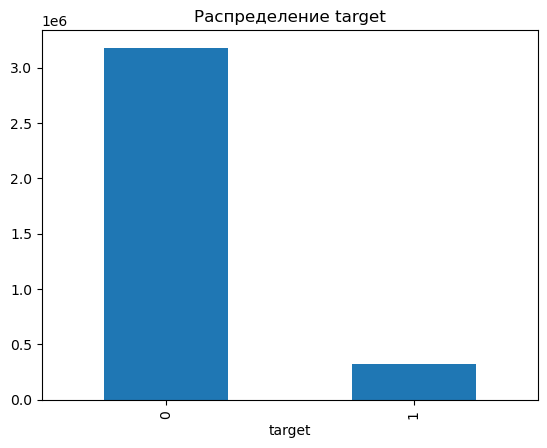

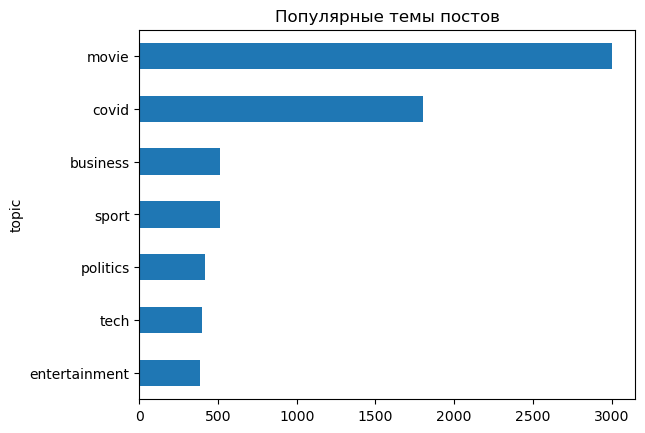

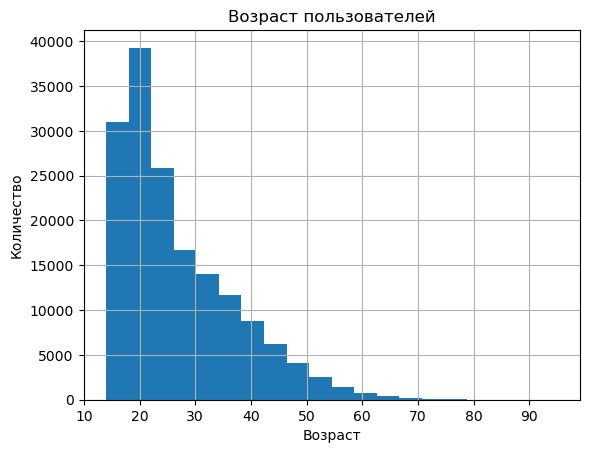

In [ ]:
import matplotlib.pyplot as plt

print('Пользователи:', df_user_data.shape)
print('Посты:', df_post_text.shape)
print('Просмотры:', df_feed_data.shape)
print('Даты просмотров:', df_feed_data['timestamp'].min(), '-', df_feed_data['timestamp'].max())

print('\nПервые пользователи:')
display(df_user_data.head())

print('Пропуски в данных пользователей:')
display(df_user_data.isna().sum().sort_values(ascending=False).head(10))

print('Первые посты:')
display(df_post_text[['post_id', 'topic', 'text']].head())

print('Пропуски в данных постов:')
display(df_post_text.isna().sum().sort_values(ascending=False).head(10))

print('Распределение таргета:')
display(df_feed_data['target'].value_counts().sort_index())

df_feed_data['target'].value_counts().sort_index().plot(kind='bar', title='Распределение target')
plt.show()

df_post_text['topic'].value_counts().head(10).sort_values().plot(kind='barh', title='Популярные темы постов')
plt.show()

df_user_data['age'].hist(bins=20)
plt.title('Возраст пользователей')
plt.xlabel('Возраст')
plt.ylabel('Количество')
plt.show()

In [5]:
df_feed_data = df_feed_data.sort_values('timestamp', kind='stable').reset_index(drop=True)
split_idx = int(len(df_feed_data) * 0.8)
feed_train = df_feed_data.iloc[:split_idx].reset_index(drop=True)
feed_test = df_feed_data.iloc[split_idx:].reset_index(drop=True)
print('train:', feed_train.shape, 'test:', feed_test.shape)

train: (2800000, 5) test: (700000, 5)


## 3. Признаки пользователей

In [6]:
# добавляем возрастную группу и считаем пользователей с такой же страной и городом

df_user_data['age_group'] = pd.cut(
    df_user_data['age'], bins=[0, 17, 25, 35, 150],
    labels=['teens', 'youth', 'adults', 'seniors'],
).astype(str)

city_counts = df_user_data.groupby(['country', 'city'])['user_id'].transform('count')
df_user_data['country_city_count'] = city_counts.astype('uint16')

USER_FEATURE_COLS = ['user_id', 'gender', 'age', 'country', 'city', 'exp_group', 'os', 'source',
                      'age_group', 'country_city_count']
user_static = df_user_data[USER_FEATURE_COLS].copy()
user_static.head()

,user_id,gender,age,country,city,exp_group,os,source,age_group,country_city_count
0,200,1,34,Russia,Degtyarsk,3,Android,ads,adults,20
1,201,0,37,Russia,Abakan,0,Android,ads,seniors,241
2,202,1,17,Russia,Smolensk,4,Android,ads,teens,434
3,203,0,18,Russia,Moscow,1,iOS,ads,youth,21874
4,204,0,36,Russia,Anzhero-Sudzhensk,3,Android,ads,seniors,105


## 4. Признаки постов


In [9]:
# считаем текстовые признаки постов и добавляем их в датафрейм

df_post_text['text'] = df_post_text['text'].fillna('').astype(str)
df_post_text['topic'] = df_post_text['topic'].fillna('unknown').astype(str)
df_post_text['text_len'] = df_post_text['text'].str.len().astype('int32')
df_post_text['word_count'] = df_post_text['text'].str.split().str.len().fillna(0).astype('int32')
df_post_text['avg_word_len'] = (
    (df_post_text['text_len'] / df_post_text['word_count'].replace(0, np.nan))
    .fillna(0.0).astype('float32')
)

In [7]:
# делаем TF-IDF векторизацию текста постов и применяем SVD для снижения размерности, затем кластеризуем посты с помощью KMeans

tfidf = TfidfVectorizer(max_features=30000, min_df=2, max_df=0.95, stop_words='english')
tfidf_matrix = tfidf.fit_transform(df_post_text['text'])

svd_model = TruncatedSVD(n_components=64, random_state=42)
post_vectors = svd_model.fit_transform(tfidf_matrix).astype('float32')

kmeans = KMeans(n_clusters=16, random_state=42, n_init=10)
text_cluster = kmeans.fit_predict(post_vectors).astype('uint8')
dist_cluster = kmeans.transform(post_vectors).astype('float32')

print('объяснённая дисперсия SVD:', round(svd_model.explained_variance_ratio_.sum(), 3))
print('размеры кластеров:', np.bincount(text_cluster))

объяснённая дисперсия SVD: 0.108
размеры кластеров: [  31 1647  194  233  105  781  748  144  179  221  714  106  121  578
  511  710]


In [10]:
# номера кластеров

dist_cols = [f'dist_cluster_{i}' for i in range(kmeans.n_clusters)]
post_static = df_post_text[['post_id', 'topic', 'text', 'text_len', 'word_count', 'avg_word_len']].copy()
post_static['text_cluster'] = text_cluster
post_static = pd.concat([post_static.reset_index(drop=True),
                          pd.DataFrame(dist_cluster, columns=dist_cols)], axis=1)
post_static.head()

,post_id,topic,text,text_len,word_count,avg_word_len,text_cluster,dist_cluster_0,dist_cluster_1,dist_cluster_2,...,dist_cluster_6,dist_cluster_7,dist_cluster_8,dist_cluster_9,dist_cluster_10,dist_cluster_11,dist_cluster_12,dist_cluster_13,dist_cluster_14,dist_cluster_15
0,1,business,UK economy facing major risks\n\nThe UK manufa...,1967,324,6.070988,6,0.565487,0.450893,0.464003,...,0.352864,0.573821,0.468995,0.518843,0.503209,0.566842,0.596518,0.470695,0.449017,0.484449
1,2,business,Aids and climate top Davos agenda\n\nClimate c...,2701,448,6.029018,6,0.491297,0.352964,0.359812,...,0.270149,0.500386,0.359439,0.343817,0.421140,0.498063,0.530807,0.376802,0.365028,0.395746
2,3,business,Asian quake hits European shares\n\nShares in ...,3408,546,6.241758,6,0.495738,0.357294,0.400019,...,0.251039,0.498243,0.396322,0.475267,0.426353,0.500206,0.533863,0.386244,0.378097,0.399183
3,4,business,India power shares jump on debut\n\nShares in ...,1026,173,5.930636,6,0.529203,0.378980,0.400382,...,0.288004,0.499578,0.379413,0.472296,0.437050,0.512723,0.544520,0.400907,0.397146,0.418602
4,5,business,Lacroix label bought by US firm\n\nLuxury good...,889,150,5.926667,6,0.389467,0.184703,0.281582,...,0.141008,0.397395,0.226306,0.348883,0.290183,0.390402,0.433727,0.228437,0.225659,0.257341


## 5. Временные признаки

In [11]:
# создали функцию для временных признаков

def build_dt_features(ts: pd.Series) -> pd.DataFrame:
    out = pd.DataFrame(index=ts.index)
    out['year'] = ts.dt.year.astype('uint16')
    out['month'] = ts.dt.month.astype('category')
    out['day'] = ts.dt.day.astype('category')
    out['dayofweek'] = (ts.dt.dayofweek + 1).astype('category')
    out['is_weekend'] = ts.dt.dayofweek.isin([5, 6]).astype('category')
    out['hour'] = ts.dt.hour.astype('category')

    part_of_day = pd.Series('night', index=ts.index)
    part_of_day[(ts.dt.hour >= 6) & (ts.dt.hour < 12)] = 'morning'
    part_of_day[(ts.dt.hour >= 12) & (ts.dt.hour < 18)] = 'afternoon'
    part_of_day[(ts.dt.hour >= 18) & (ts.dt.hour < 24)] = 'evening'
    out['part_of_day'] = part_of_day.to_numpy()
    return out

## 6. Сборка выборки

Объединяем таблицы и выбираем признаки по типам.

In [12]:
# создали функцию для сборки признаков

def assemble(feed, user_features, post_features):
    dt_feats = build_dt_features(feed['timestamp'])
    df = pd.concat([dt_feats, feed[['user_id', 'post_id', 'target']].reset_index(drop=True)], axis=1)
    df = df.merge(user_features, on='user_id', how='inner')
    df = df.merge(post_features.drop(columns=['text']), on='post_id', how='inner')
    return df


train_set = assemble(feed_train, user_static, post_static)
test_set = assemble(feed_test, user_static, post_static)

features_cols = train_set.drop(columns=['user_id', 'post_id', 'target']).columns.tolist()

for df in (train_set, test_set):
    for col in df[features_cols].select_dtypes(include='object').columns:
        df[col] = df[col].astype(str)
    for col in df[features_cols].select_dtypes(include='number').columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype('float32')

cat_cols = train_set[features_cols].select_dtypes(include=['object', 'category']).columns.tolist()

print('признаков:', len(features_cols))
print(features_cols)
print('train/test:', train_set.shape, test_set.shape)

признаков: 37
['year', 'month', 'day', 'dayofweek', 'is_weekend', 'hour', 'part_of_day', 'gender', 'age', 'country', 'city', 'exp_group', 'os', 'source', 'age_group', 'country_city_count', 'topic', 'text_len', 'word_count', 'avg_word_len', 'text_cluster', 'dist_cluster_0', 'dist_cluster_1', 'dist_cluster_2', 'dist_cluster_3', 'dist_cluster_4', 'dist_cluster_5', 'dist_cluster_6', 'dist_cluster_7', 'dist_cluster_8', 'dist_cluster_9', 'dist_cluster_10', 'dist_cluster_11', 'dist_cluster_12', 'dist_cluster_13', 'dist_cluster_14', 'dist_cluster_15']
train/test: (2800000, 40) (700000, 40)


## 7. Обучаем модель

In [13]:
cut = int(len(train_set) * 0.9)
train_pool = Pool(train_set.loc[:cut - 1, features_cols], train_set.loc[:cut - 1, 'target'], cat_features=cat_cols)
val_pool = Pool(train_set.loc[cut:, features_cols], train_set.loc[cut:, 'target'], cat_features=cat_cols)

model = CatBoostClassifier(
    iterations=2000, depth=6, learning_rate=0.06, l2_leaf_reg=3,
    eval_metric='AUC', random_seed=42, verbose=100,
)
model.fit(train_pool, eval_set=val_pool, use_best_model=True, early_stopping_rounds=100)
print('деревьев в модели:', model.tree_count_)

0:	test: 0.5055368	best: 0.5055368 (0)	total: 903ms	remaining: 30m 5s
100:	test: 0.6918785	best: 0.6918785 (100)	total: 1m 25s	remaining: 26m 53s
200:	test: 0.7008432	best: 0.7008432 (200)	total: 3m 9s	remaining: 28m 12s
300:	test: 0.7059850	best: 0.7059850 (300)	total: 4m 56s	remaining: 27m 54s
400:	test: 0.7088473	best: 0.7088473 (400)	total: 6m 39s	remaining: 26m 34s
500:	test: 0.7116739	best: 0.7116760 (497)	total: 8m 21s	remaining: 25m
600:	test: 0.7136450	best: 0.7136450 (600)	total: 10m 6s	remaining: 23m 31s
700:	test: 0.7154707	best: 0.7154707 (700)	total: 11m 51s	remaining: 21m 58s
800:	test: 0.7173229	best: 0.7173233 (799)	total: 13m 38s	remaining: 20m 25s
900:	test: 0.7188683	best: 0.7188683 (900)	total: 15m 25s	remaining: 18m 49s
1000:	test: 0.7201354	best: 0.7201354 (1000)	total: 17m 12s	remaining: 17m 10s
1100:	test: 0.7218920	best: 0.7218920 (1100)	total: 19m	remaining: 15m 30s
1200:	test: 0.7225584	best: 0.7227951 (1190)	total: 20m 48s	remaining: 13m 50s
1300:	test: 0.7

## 8. Проверка модели

In [14]:
proba = model.predict_proba(test_set[features_cols])[:, 1]
print('ROC-AUC:', round(roc_auc_score(test_set['target'], proba), 4))
print('PR-AUC: ', round(average_precision_score(test_set['target'], proba), 4))

ROC-AUC: 0.7125
PR-AUC:  0.1805


## 9. Сохраняем модель и данные

In [ ]:
# признаки юзеров

final_user_features = user_static.copy()
final_user_features['user_id'] = final_user_features['user_id'].astype('uint32')
final_user_features['gender'] = final_user_features['gender'].astype('uint8')
final_user_features['age'] = final_user_features['age'].astype('uint8')
final_user_features['exp_group'] = final_user_features['exp_group'].astype('uint8')
for c in ('country', 'city', 'os', 'source', 'age_group'):
    final_user_features[c] = final_user_features[c].astype(str)
final_user_features['country_city_count'] = final_user_features['country_city_count'].astype('uint16')

In [ ]:
# признаки постов

final_post_features = post_static.copy()
final_post_features['post_id'] = final_post_features['post_id'].astype('uint16')
final_post_features['topic'] = final_post_features['topic'].astype(str)
final_post_features['text'] = final_post_features['text'].astype(str)
final_post_features['text_cluster'] = final_post_features['text_cluster'].astype('uint8')
final_post_features['text_len'] = final_post_features['text_len'].astype('uint32')
final_post_features['word_count'] = final_post_features['word_count'].astype('uint16')
final_post_features['avg_word_len'] = final_post_features['avg_word_len'].astype('float16')
for c in dist_cols:
    final_post_features[c] = final_post_features[c].astype('float16')

In [ ]:
# лайки из загруженной истории

all_likes = df_feed_data.loc[df_feed_data['target'] == 1].groupby('user_id')['post_id'].agg(list)
final_user_likes = pd.DataFrame({
    'user_id': user_static['user_id'],
    'liked_posts': user_static['user_id'].map(all_likes).apply(lambda v: v if isinstance(v, list) else []),
})
final_user_likes['user_id'] = final_user_likes['user_id'].astype('uint32')
final_user_likes.head()

In [ ]:
with open('model.pkl', 'wb') as f:
    pickle.dump(model, f)


final_user_features.to_sql(
    'rec_user_features', con=postgres_connection(), if_exists='replace', index=False,
    chunksize=10000,
)
final_post_features.to_sql(
    'rec_post_features', con=postgres_connection(), if_exists='replace', index=False,
    chunksize=10000,
)
final_user_likes.to_sql(
    'rec_user_likes', con=postgres_connection(), if_exists='replace', index=False,
    dtype={'liked_posts': ARRAY(BIGINT)}, chunksize=10000,
)
print('Сохранение признаков в БД завершено')

## 10. Проверяем рекомендации

In [ ]:
import requests

test_user = int(feed_test['user_id'].iloc[0])
test_dt = feed_test['timestamp'].iloc[0].isoformat()

response = requests.get(
    "http://127.0.0.1:8000/post/recommendations/",
    params={"user_id": test_user, "dt": test_dt, "limit": 5},
)
print(f"Рекомендации для user_id = {test_user}:")
for rec in response.json():
    print(rec["id"], rec["topic"], rec["text"][:80])